# Data regularization script in preparation for WinHotine - Geoid Modelling Software

The purpose of this Python notebook is to solve the natural irregularities that
arise on field, when taking the measurements needed for the WinHotine software.

Considering that the original LSMHSOFT C++ software provided by Abbak, R.A., Ellmann, A. & Ustun, A. only works using an exactly regular mesh of measurments, what we do is to first analyze the input data to determine the appropiate bounds and inner intervals for our regular grid, then generate this perfect regular grid point coordinates and finally take the nearest measurement for each point and translated to the regular grid point.

Finally, a basic analysis of the quantity of translated distance is performed through a histogram.

In [1]:
!pip install xlrd
!pip install pandas
!pip install matplotlib
!pip install numpy
!pip install folium

In [2]:
import pandas as pd

In [3]:
elevacion = pd.read_csv("ELEVACION.XYZ", delimiter = r"\s+", names=["x", "y", "z"])
perturba = pd.read_csv("perturbacion.XYZ", delimiter = r"\s+", names=["x", "y", "z"])
    
#elevacion = pd.read_excel("elev1.xls", engine="xlrd", names=["y", "x", "z"])
#perturba = pd.read_excel("per1.xls", engine="xlrd", names=["y", "x", "z"])

In [4]:
elevacion

,x,y,z
0,27.27083,-109.3125,82.00
1,27.35417,-109.3125,158.95
2,27.39583,-109.3125,192.04
3,27.31250,-109.3125,246.25
4,27.52083,-109.3125,262.00
...,...,...,...
15044,27.89580,-113.5625,111.60
15045,27.93750,-113.5625,136.00
15046,27.97920,-113.5625,160.00
15047,27.27080,-113.5625,200.00


In [5]:
perturba

,x,y,z
0,27.27083,-109.3125,-38.3517
1,27.35417,-109.3125,-43.6905
2,27.39583,-109.3125,-37.5536
3,27.31250,-109.3125,-6.4496
4,27.52083,-109.3125,-45.5378
...,...,...,...
15044,27.89580,-113.5625,-8.0242
15045,27.93750,-113.5625,-3.8747
15046,27.97920,-113.5625,1.3991
15047,27.27080,-113.5625,-25.6881


In [6]:
import folium

In [7]:
def genmap(df):
    locinicial = [df.x.mean(), df.y.mean()]
    df_map = folium.Map(location=locinicial, zoom_start=7)
    for i in df.index:
        val = f"z = {df.z[i]}"
        folium.CircleMarker([df.x[i], df.y[i]], tooltip=val, radius=1, weight=1).add_to(df_map)
    return df_map

In [10]:
genmap(elevacion)

In [11]:
def get_bounds(df):
    min_x = elevacion.x.min()
    max_x = elevacion.x.max()
    min_y = elevacion.y.min()
    max_y = elevacion.y.max()

    print(f'x: {min_x}, {max_x}')
    print(f'y: {min_y}, {max_y}')

get_bounds(elevacion)
get_bounds(perturba)

x: 27.2598, 30.7042
y: -113.5625, -109.3125
x: 27.2598, 30.7042
y: -113.5625, -109.3125


In [12]:
len(set(elevacion.x))

5062

In [13]:
len(set(elevacion.y))

4971

In [14]:
196 * 180 == len(elevacion)

False

We have a span in x of span_x = 3.4444. The distance between points for this span_x should be 0.00068044...
We choose a target distance of 0.02, which is a divisor of 1 and has a finite decimal representation.
The closest span that fits with this distance is 3.44.
We adjust our min_x and max_x to fit this.
min_x = 27.2598, max_x = 30.6998

The span in y is span_y = 4.25. We also choose 0.02 as distance and the adjusted span_y = 4.24.
We adjust min_y = -113.5625, max_y = -109.3225

In [15]:
min_x = 27.2598
max_x = 30.6998
min_y = -113.5625
max_y = -109.3225
w = 172
h = 212

In [16]:
import numpy as np

In [17]:
def own_linspace(start, end, w, round_to=None):
    data = []
    point = start
    dist = (end - start) / w
    if end > start:
        while point <= end:
            data.append(point)
            point += dist
            if round_to:
                point = np.round(point, round_to)
    else:
        while point >= end:
            data.append(point)
            point += dist
            if round_to:
                point = np.round(point, round_to)
    return data


In [18]:
print(own_linspace(max_x, min_x, w, round_to = 8))
print(own_linspace(min_y, max_y, h, round_to = 10))

[30.6998, np.float64(30.6798), np.float64(30.6598), np.float64(30.6398), np.float64(30.6198), np.float64(30.5998), np.float64(30.5798), np.float64(30.5598), np.float64(30.5398), np.float64(30.5198), np.float64(30.4998), np.float64(30.4798), np.float64(30.4598), np.float64(30.4398), np.float64(30.4198), np.float64(30.3998), np.float64(30.3798), np.float64(30.3598), np.float64(30.3398), np.float64(30.3198), np.float64(30.2998), np.float64(30.2798), np.float64(30.2598), np.float64(30.2398), np.float64(30.2198), np.float64(30.1998), np.float64(30.1798), np.float64(30.1598), np.float64(30.1398), np.float64(30.1198), np.float64(30.0998), np.float64(30.0798), np.float64(30.0598), np.float64(30.0398), np.float64(30.0198), np.float64(29.9998), np.float64(29.9798), np.float64(29.9598), np.float64(29.9398), np.float64(29.9198), np.float64(29.8998), np.float64(29.8798), np.float64(29.8598), np.float64(29.8398), np.float64(29.8198), np.float64(29.7998), np.float64(29.7798), np.float64(29.7598), np.

In [19]:
def dist(x_1, y_1, x_2, y_2):
    return np.sqrt(np.power(x_1 - x_2, 2) + np.power(y_1 -y_2, 2))

In [20]:
def find_closest_point(df, x, y):
    closest = (float("+inf"), float("+inf"), float("+inf"))
    for i in df[(df['x'] < x + 0.03) & (df['x'] > x - 0.03) & (df['y'] < y + 0.03) & (df['y'] > y - 0.03)].index:
        if dist(x, y, df.x[i], df.y[i]) < dist(x, y, closest[0], closest[1]):
            closest = (df.x[i], df.y[i], df.z[i])
    if closest == (float('+inf'), float('+inf'), float('+inf')):
        for i in df.index:
            if dist(x, y, df.x[i], df.y[i]) < dist(x, y, closest[0], closest[1]):
                closest = (df.x[i], df.y[i], df.z[i])

    return closest


In [21]:
find_closest_point(elevacion, 30.71578, -113.26)

(np.float64(30.6875), np.float64(-113.2708), np.float64(0.0))

In [22]:
def gengrid(df, min_x, max_x, min_y, max_y, w, h):
    data = []
    for x in own_linspace(max_x, min_x, w, 6):
        for y in own_linspace(min_y, max_y, h, 6):
            closest = find_closest_point(df, x, y)
            data.append([x, y, closest[2], dist(x, y, closest[0], closest[1])])
    return pd.DataFrame(data, columns=["x", "y", "z", "d"])

In [23]:
elevacion_grid = gengrid(elevacion, min_x, max_x, min_y, max_y, w, h)
elevacion_grid

,x,y,z,d
0,30.6998,-113.5625,0.0,0.012300
1,30.6998,-113.5425,0.0,0.023480
2,30.6998,-113.5225,0.0,0.012417
3,30.6998,-113.5025,0.0,0.022049
4,30.6998,-113.4825,0.0,0.012735
...,...,...,...,...
36844,27.2598,-109.4025,90.0,0.011404
36845,27.2598,-109.3825,79.0,0.016015
36846,27.2598,-109.3625,79.0,0.011557
36847,27.2598,-109.3425,79.8,0.016058


In [24]:
perturba_grid = gengrid(perturba, min_x, max_x, min_y, max_y, w, h)
perturba_grid

,x,y,z,d
0,30.6998,-113.5625,-18.0273,0.012300
1,30.6998,-113.5425,-18.0273,0.023480
2,30.6998,-113.5225,-17.9643,0.012417
3,30.6998,-113.5025,-17.9643,0.022049
4,30.6998,-113.4825,-18.4023,0.012735
...,...,...,...,...
36844,27.2598,-109.4025,-23.0919,0.011404
36845,27.2598,-109.3825,-32.4351,0.016015
36846,27.2598,-109.3625,-42.5224,0.011557
36847,27.2598,-109.3425,-31.3176,0.016058


In [25]:
(len(set(elevacion.x)), len(set(elevacion.y)))

(5062, 4971)

In [26]:
(len(set(elevacion_grid.x)), len(set(elevacion_grid.y)))

(173, 213)

In [27]:
import matplotlib.pyplot as plt

(array([  3.,  73.,  88.,  28.,  36., 162., 170., 132., 127., 192., 209.,
        317.,  89., 268., 363., 221., 238., 305., 409., 333., 173., 324.,
        456., 328., 380., 346., 494., 361., 437., 492., 417., 453., 502.,
        170., 644., 668., 365., 418., 629., 463., 571., 460., 631., 669.,
        454., 528., 661., 593., 552., 465., 467., 844., 582., 434., 613.,
        838., 475., 510., 734., 605., 482., 611., 415., 840., 609., 457.,
        674., 537., 628., 657., 379., 745., 601., 433., 305., 455., 493.,
        275., 180., 349., 401., 177., 182., 176., 320., 244.,  13., 167.,
        242., 148.,  12., 161., 216.,   4.,   3., 137.,  79.,   1.,   2.,
         70.]),
 array([0.0002    , 0.00048533, 0.00077066, 0.001056  , 0.00134133,
        0.00162666, 0.00191199, 0.00219732, 0.00248266, 0.00276799,
        0.00305332, 0.00333865, 0.00362398, 0.00390932, 0.00419465,
        0.00447998, 0.00476531, 0.00505064, 0.00533598, 0.00562131,
        0.00590664, 0.00619197, 0.0064773 , 0.

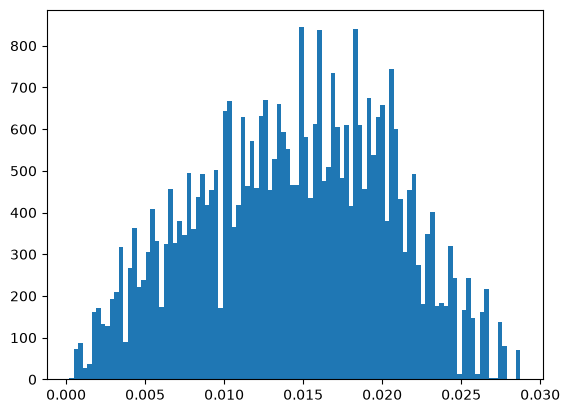

In [28]:
plt.hist(elevacion_grid.d, bins=100)

In [31]:
elevacion_grid.to_csv("elevacion1_mde_180826.XYZ", sep=' ', header=False, index=False, columns=['x', 'y', 'z'])
perturba_grid.to_csv("perturbacion1_mde_180826.XYZ", sep=' ', header=False, index=False, columns=['x', 'y', 'z'])